Q13. Detect outliers using IQR and replace extreme values with median.

In [1]:
import pandas as pd

df = pd.read_csv('salaries.csv')

q1 = df['Salary'].quantile(0.25)
q3 = df['Salary'].quantile(0.75)
iqr = q3 - q1
low = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr
print(low, high)

outliers = (df['Salary'] < low) | (df['Salary'] > high)
print(df[outliers])

df.loc[outliers, 'Salary'] = df['Salary'].median()
print(df)

24500.0 42500.0
  Name  Salary
7    H  250000
  Name  Salary
0    A   30000
1    B   32000
2    C   35000
3    D   31000
4    E   33000
5    F   34000
6    G   36000
7    H   33500
8    I   29000
9    J   38000


Q14. Perform correlation and feature-importance analysis.

          Engine    Weight       Age     Price
Engine  1.000000  0.994837 -0.949735  0.999146
Weight  0.994837  1.000000 -0.962744  0.994087
Age    -0.949735 -0.962744  1.000000 -0.944140
Price   0.999146  0.994087 -0.944140  1.000000


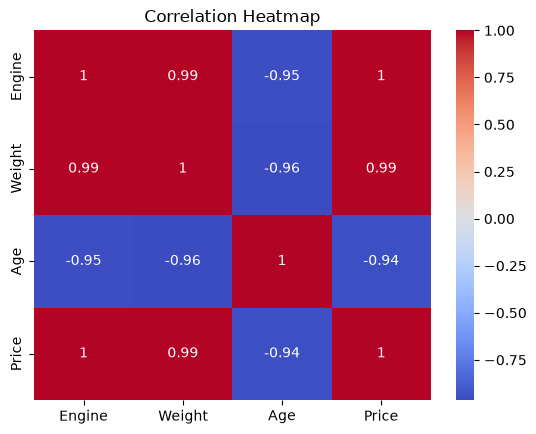

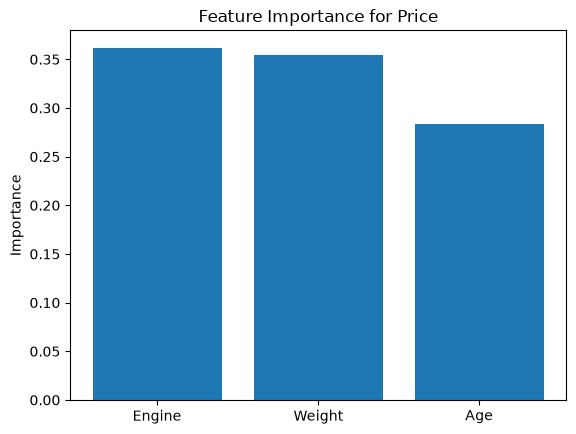

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor

df = pd.read_csv('cars.csv')
print(df.corr())

sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

X = df[['Engine', 'Weight', 'Age']]
y = df['Price']
model = RandomForestRegressor(random_state=42)
model.fit(X, y)

plt.bar(X.columns, model.feature_importances_)
plt.ylabel('Importance')
plt.title('Feature Importance for Price')
plt.show()

Q15. Create subplots for line, bar, and density plots of multiple variables. Add suitable titles and axis labels.

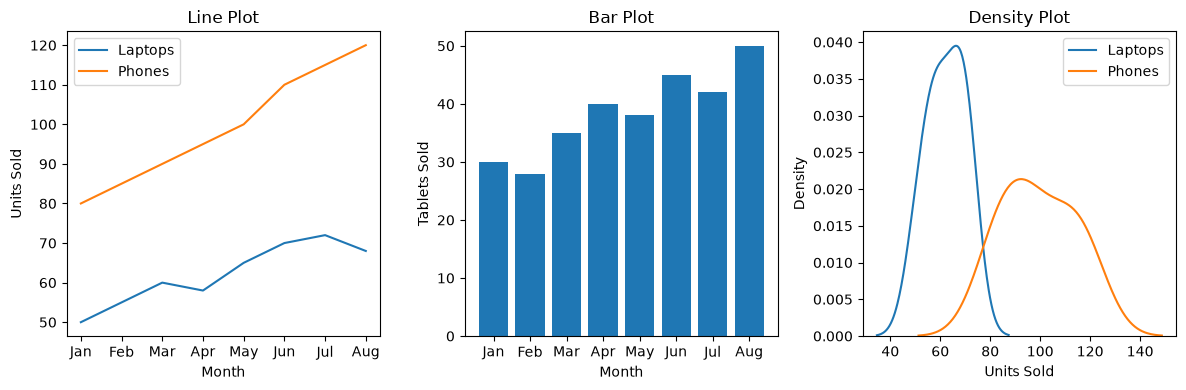

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('monthly_sales.csv')
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.plot(df['Month'], df['Laptops'], label='Laptops')
plt.plot(df['Month'], df['Phones'], label='Phones')
plt.title('Line Plot')
plt.xlabel('Month')
plt.ylabel('Units Sold')
plt.legend()

plt.subplot(1, 3, 2)
plt.bar(df['Month'], df['Tablets'])
plt.title('Bar Plot')
plt.xlabel('Month')
plt.ylabel('Tablets Sold')

plt.subplot(1, 3, 3)
sns.kdeplot(df['Laptops'], label='Laptops')
sns.kdeplot(df['Phones'], label='Phones')
plt.title('Density Plot')
plt.xlabel('Units Sold')
plt.legend()

plt.tight_layout()
plt.show()

Q16. Train and evaluate a Multiple Linear Regression model. Plot the predicted-versus-actual values or regression results and examine the residuals.

0.012188267677898316
0.9998325838510713


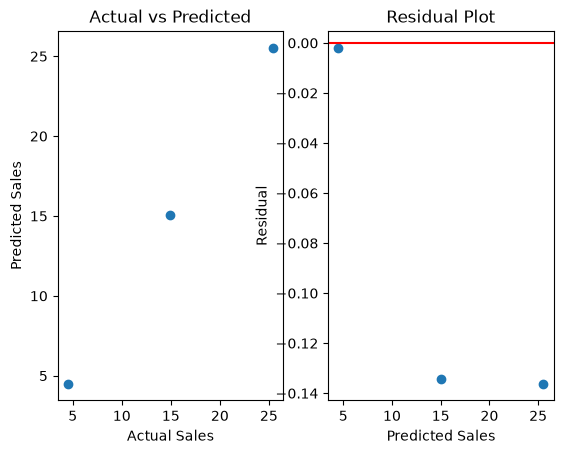

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

df = pd.read_csv('advertising.csv')
X = df[['TV', 'Radio']]
y = df['Sales']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)
pred = model.predict(X_test)

print(mean_squared_error(y_test, pred))
print(r2_score(y_test, pred))
residual = y_test - pred

plt.subplot(1, 2, 1)
plt.scatter(y_test, pred)
plt.xlabel('Actual Sales')
plt.ylabel('Predicted Sales')
plt.title('Actual vs Predicted')

plt.subplot(1, 2, 2)
plt.scatter(pred, residual)
plt.axhline(0, color='red')
plt.xlabel('Predicted Sales')
plt.ylabel('Residual')
plt.title('Residual Plot')
plt.show()